# Bayesian optimisation of the control parameters

Step 2 of `1_main_experiment.ipynb` tunes the control parameters of SGD, SCG and LeapFrog with a
grid search. This notebook tunes them again with **Bayesian optimisation (BO)** and compares the
two. The network sizes stay those of Step 1, and every search gets as many trials as its grid has
settings: 49 for SGD, 9 for SCG and 36 for LeapFrog.

One search works as follows:

1. Train the default setting and four settings spread over the search space by a Latin hypercube.
2. Fit a Gaussian process (GP) to the validation errors observed so far.
3. Pick the candidate setting with the largest expected improvement (EI).
4. Train that setting, add its validation error to the observations and go back to 2.

For a GP with predictive mean $\mu(x)$ and standard deviation $s(x)$, and the lowest observed
value $b$, the expected improvement of a setting $x$ is

$$\mathrm{EI}(x) = (b - \mu(x))\,\Phi(z) + s(x)\,\phi(z), \qquad z = \frac{b - \mu(x)}{s(x)},$$

where $\Phi$ and $\phi$ are the standard normal distribution and density functions.
EI is large for a low predicted error or a large uncertainty.

### Contents
1. Settings
2. Code from notebook 1
3. The search space
4. The Bayesian search
5. Running the searches
6. Grid search against Bayesian optimisation: validation error
7. Final evaluation on the complete datasets
8. Friedman and Nemenyi tests
9. Search progress

### Running the notebook
The searches and the final runs are saved in `results/bayesian/`. When a file exists, the notebook
reads it instead of training again. Delete `trials.csv` and `final.csv` to repeat the experiment
(about half an hour).

## 1. Settings

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"          # one thread gives repeatable results
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn import datasets as ds
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern
from sklearn.exceptions import ConvergenceWarning

In [2]:
ALGORITHMS = ["SGD", "SCG", "LeapFrog"]
PROBLEMS = ["wine", "breast_cancer", "digits", "diabetes", "airfoil", "california"]
# Hidden units chosen in Step 1 of 1_main_experiment.ipynb (two for diabetes)
CHOSEN_HIDDEN = {"wine": 2, "breast_cancer": 2, "digits": 32, "diabetes": 2, "airfoil": 16, "california": 32}
N_TRIALS = {"SGD": 49, "SCG": 9, "LeapFrog": 36}     # the number of grid settings
N_CANDIDATES = 2048     # candidate settings scored by EI in every trial
PENALTY_ERROR = 100.0   # errors above this (or nan) mark a diverged setting
MAX_EPOCHS = 200        # gradient calculations per training run
MAX_PATTERNS = 5000     # size cap for the searches
SEED = 0                # subsample of California housing
TUNE_SEED = 1           # folds of the searches (the folds of Step 2)
FINAL_SPLIT_SEED = 42   # folds of the final evaluation (the folds of Step 3)

MAIN_RESULTS = "results"                     # results of 1_main_experiment.ipynb
RESULTS = os.path.join("results", "bayesian")
os.makedirs(RESULTS, exist_ok=True)
COLOURS = {"SGD": "#1769aa", "SCG": "#c36c18", "LeapFrog": "#008675"}

np.seterr(over="ignore", invalid="ignore", divide="ignore")   # diverged runs are handled below
warnings.simplefilter("ignore", ConvergenceWarning)            # GP fits at a length-scale bound

## 2. Code from notebook 1
The network, the training algorithms and the folds are copied unchanged from
`1_main_experiment.ipynb`, so that this notebook runs on its own.

In [3]:
def make_network(n_inputs, n_hidden, n_outputs, task):
    """Store the layer sizes and the task (classification or regression)."""
    return {"n_inputs": n_inputs, "n_hidden": n_hidden, "n_outputs": n_outputs, "task": task}


def init_weights(net, seed):
    """Uniform weights in [-1/sqrt(fan-in), 1/sqrt(fan-in)], returned as one flat vector."""
    rng = np.random.RandomState(seed)
    n_in, n_hid, n_out = net["n_inputs"], net["n_hidden"], net["n_outputs"]
    W1 = rng.uniform(-1, 1, size=(n_hid, n_in)) / np.sqrt(n_in)
    b1 = rng.uniform(-1, 1, size=n_hid) / np.sqrt(n_in)
    W2 = rng.uniform(-1, 1, size=(n_out, n_hid)) / np.sqrt(n_hid)
    b2 = rng.uniform(-1, 1, size=n_out) / np.sqrt(n_hid)
    return np.concatenate([W1.ravel(), b1, W2.ravel(), b2])


def unpack_weights(w, net):
    """Split the flat weight vector into W1, b1 (hidden layer) and W2, b2 (output layer)."""
    n_in, n_hid, n_out = net["n_inputs"], net["n_hidden"], net["n_outputs"]
    a = n_hid * n_in
    b = a + n_hid
    c = b + n_out * n_hid
    return w[:a].reshape(n_hid, n_in), w[a:b], w[b:c].reshape(n_out, n_hid), w[c:]


def softmax(Z):
    """Row-wise softmax. Subtracting the row maximum avoids overflow."""
    Z = Z - Z.max(axis=1, keepdims=True)
    expZ = np.exp(Z)
    return expZ / expZ.sum(axis=1, keepdims=True)


def forward(w, X, net):
    """Return the hidden activations H and the network outputs Y."""
    W1, b1, W2, b2 = unpack_weights(w, net)
    H = np.tanh(X @ W1.T + b1)
    Z = H @ W2.T + b2
    if net["task"] == "classification":
        return H, softmax(Z)
    return H, Z


def compute_loss(w, X, T, net):
    """Cross-entropy for classification and half the mean squared error for regression."""
    H, Y = forward(w, X, net)
    n = X.shape[0]
    if net["task"] == "classification":
        return -np.sum(T * np.log(Y + 1e-12)) / n
    return 0.5 * np.sum((Y - T) ** 2) / n


def compute_gradient(w, X, T, net):
    """Backpropagation: the gradient of compute_loss with respect to the weight vector."""
    W1, b1, W2, b2 = unpack_weights(w, net)
    H, Y = forward(w, X, net)
    n = X.shape[0]
    delta_out = (Y - T) / n
    delta_hidden = delta_out @ W2 * (1 - H ** 2)
    return np.concatenate([(delta_hidden.T @ X).ravel(), delta_hidden.sum(axis=0),
                           (delta_out.T @ H).ravel(), delta_out.sum(axis=0)])


def compute_error(w, X, T, net):
    """Misclassification rate for classification and mean squared error for regression."""
    H, Y = forward(w, X, net)
    if net["task"] == "classification":
        return np.mean(np.argmax(Y, axis=1) != np.argmax(T, axis=1))
    return np.mean((Y - T) ** 2)

In [4]:
def train_sgd(w, X, T, net, learning_rate, momentum, batch_size, max_epochs, seed, callback=None):
    """Mini-batch gradient descent with momentum. One epoch is one pass over the training set."""
    rng = np.random.RandomState(seed)
    w = w.copy()
    velocity = np.zeros(len(w))
    n = X.shape[0]
    loss_history = []
    for epoch in range(max_epochs):
        order = rng.permutation(n)
        for start in range(0, n, batch_size):
            batch = order[start:start + batch_size]
            gradient = compute_gradient(w, X[batch], T[batch], net)
            velocity = momentum * velocity - learning_rate * gradient
            w = w + velocity
        loss_history.append(compute_loss(w, X, T, net))
        if callback:
            callback(w)
    return w, loss_history


def train_scg(w, X, T, net, sigma, lambda_1, max_epochs, callback=None):
    """Scaled conjugate gradient (Moller, 1993)."""
    w = w.copy()
    N = len(w)
    lam = lambda_1
    lam_bar = 0.0
    r = -compute_gradient(w, X, T, net)
    p = r.copy()
    success = True
    k = 1
    loss = compute_loss(w, X, T, net)
    loss_history = [loss]
    if callback:
        callback(w)
    delta = 0.0
    while len(loss_history) < max_epochs:
        if k > 10 * max_epochs:
            raise FloatingPointError("SCG exceeded trial limit")
        p_squared = p @ p
        if not np.isfinite(p_squared):
            raise FloatingPointError("SCG non-finite direction")
        if p_squared <= 0:
            break
        if success:
            sigma_k = sigma / np.sqrt(p_squared)
            gradient_shifted = compute_gradient(w + sigma_k * p, X, T, net)
            loss_history.append(loss)
            if callback:
                callback(w)
            s = (gradient_shifted + r) / sigma_k
            delta = p @ s
        delta = delta + (lam - lam_bar) * p_squared
        if delta <= 0:
            lam_bar = 2 * (lam - delta / p_squared)
            delta = -delta + lam * p_squared
            lam = lam_bar
        mu = p @ r
        if not np.isfinite([mu, delta]).all():
            raise FloatingPointError("SCG non-finite curvature")
        if mu == 0 or delta == 0:
            break
        alpha = mu / delta
        loss_new = compute_loss(w + alpha * p, X, T, net)
        Delta = 2 * delta * (loss - loss_new) / mu ** 2
        if Delta >= 0:
            w = w + alpha * p
            loss = loss_new
            r_new = -compute_gradient(w, X, T, net)
            loss_history.append(loss)
            if callback:
                callback(w)
            lam_bar = 0.0
            success = True
            if k % N == 0:
                p = r_new
            else:
                beta = (r_new @ r_new - r_new @ r) / mu
                p = r_new + beta * p
            r = r_new
            if Delta >= 0.75:
                lam = lam / 4
        else:
            lam_bar = lam
            success = False
        if Delta < 0.25:
            lam = lam + delta * (1 - Delta) / p_squared
        if np.linalg.norm(r) < 1e-10:
            break
        k = k + 1
    loss_history = loss_history[:max_epochs]
    while len(loss_history) < max_epochs:
        loss_history.append(loss)
    return w, loss_history


def train_leapfrog(w, X, T, net, dt, max_step, m, delta_1, max_epochs, callback=None, trace=None):
    """LeapFrog LFOP1(b) (Snyman, 1983). If trace is a list, every gradient calculation adds
    the time step, the gradient norm, the sharp-turn test and the restart test to it."""
    epsilon = 1e-5
    i, j, s, p = 0, 2, 0, 1.0
    w = w.copy()
    a = -compute_gradient(w, X, T, net)
    v = 0.5 * a * dt
    loss_history = [compute_loss(w, X, T, net)]
    if callback:
        callback(w)
    w_prev, v_prev, w_final = w, v, w
    stop = False
    while len(loss_history) < max_epochs and not stop:
        if np.linalg.norm(v) * dt < max_step:
            p = p + delta_1
            dt = p * dt
        else:
            v = max_step * v / (dt * np.linalg.norm(v))
        if s >= m:
            dt = dt / 2
            w = (w + w_prev) / 2
            v = (v + v_prev) / 4
            s = 0
        w_next = w + v * dt
        while len(loss_history) < max_epochs:
            a_next = -compute_gradient(w_next, X, T, net)
            v_next = v + a_next * dt
            loss_history.append(compute_loss(w_next, X, T, net))
            if callback:
                callback(w_next)
            if trace is not None:
                trace.append({"dt": dt, "gradient_norm": np.linalg.norm(a_next),
                              "sharp_turn": a_next @ a <= 0,
                              "restart": np.linalg.norm(v_next) <= np.linalg.norm(v)})
            w_final = w_next
            if a_next @ a > 0:
                s = 0
            else:
                s = s + 1
                p = 1.0
            if np.linalg.norm(a_next) <= epsilon:
                stop = True
                break
            if np.linalg.norm(v_next) > np.linalg.norm(v):
                i = 0
                w_prev, v_prev = w, v
                w, v, a = w_next, v_next, a_next
                break
            w_midpoint = (w_next + w) / 2
            i = i + 1
            if i <= j:
                v_next = (v_next + v) / 4
            else:
                v_next = np.zeros(len(w))
                j = 1
            w_prev, v_prev = w, v
            w, v, a = w_next, v_next, a_next
            w_next = w_midpoint
    while len(loss_history) < max_epochs:
        loss_history.append(loss_history[-1])
    return w_final, loss_history


# Default control parameters (the first trial of every search)
DEFAULT_PARAMS = {
    "SGD": {"learning_rate": 0.01, "momentum": 0.9, "batch_size": 32},
    "SCG": {"sigma": 1e-4, "lambda_1": 1e-6},
    "LeapFrog": {"dt": 0.5, "max_step": 1.0, "m": 3, "delta_1": 0.001},
}


def train_network(algorithm, w, X, T, net, params, max_epochs, seed, callback=None):
    """Train with SGD, SCG or LeapFrog and return the final weights and the loss history."""
    if algorithm == "SGD":
        return train_sgd(w, X, T, net, params["learning_rate"], params["momentum"],
                         params["batch_size"], max_epochs, seed, callback)
    if algorithm == "SCG":
        return train_scg(w, X, T, net, params["sigma"], params["lambda_1"], max_epochs, callback)
    return train_leapfrog(w, X, T, net, params["dt"], params["max_step"], params["m"],
                          params["delta_1"], max_epochs, callback)

In [5]:
def subsample(X, y, task, max_patterns, seed):
    """Random sample of max_patterns rows. Classification keeps the class proportions."""
    if X.shape[0] <= max_patterns:
        return X, y
    rng = np.random.RandomState(seed)
    if task == "classification":
        keep = []
        for label in np.unique(y):
            index = np.where(y == label)[0]
            take = int(round(max_patterns * len(index) / len(y)))
            keep.append(rng.choice(index, size=take, replace=False))
        keep = np.concatenate(keep)
    else:
        keep = rng.choice(len(y), size=max_patterns, replace=False)
    keep.sort()
    return X[keep], y[keep]


def load_problems(max_patterns=MAX_PATTERNS):
    """Load the six datasets. max_patterns=None keeps every row."""
    raw = [("wine", "classification", *ds.load_wine(return_X_y=True)),
           ("breast_cancer", "classification", *ds.load_breast_cancer(return_X_y=True)),
           ("digits", "classification", *ds.load_digits(return_X_y=True)),
           ("diabetes", "regression", *ds.load_diabetes(return_X_y=True)),
           ("airfoil", "regression", *ds.fetch_openml(data_id=44957, return_X_y=True, as_frame=False)),
           ("california", "regression", *ds.fetch_california_housing(return_X_y=True))]
    problems = []
    for name, task, X, y in raw:
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y)
        if task == "regression":
            y = y.astype(np.float64)
        if max_patterns is not None:
            X, y = subsample(X, y, task, max_patterns, SEED)
        problems.append({"name": name, "task": task, "X": X, "y": y})
    return problems


def make_splits(X, y, task, n_folds, seed):
    """Stratified folds for classification and ordinary folds for regression."""
    if task == "classification":
        return list(StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed).split(X, y))
    return list(KFold(n_splits=n_folds, shuffle=True, random_state=seed).split(X))


def prepare_fold(X, y, train_index, val_index, task):
    """Standardise with the training fold and build the target matrices."""
    X_train, X_val = X[train_index], X[val_index]
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)
    std[std == 0] = 1.0
    X_train = (X_train - mean) / std
    X_val = (X_val - mean) / std
    if task == "classification":
        classes = list(np.unique(y))
        eye = np.eye(len(classes))
        T_train = eye[[classes.index(label) for label in y[train_index]]]
        T_val = eye[[classes.index(label) for label in y[val_index]]]
    else:
        y_mean, y_std = y[train_index].mean(), y[train_index].std()
        if y_std == 0:
            y_std = 1.0
        T_train = ((y[train_index] - y_mean) / y_std).reshape(-1, 1)
        T_val = ((y[val_index] - y_mean) / y_std).reshape(-1, 1)
    return X_train, T_train, X_val, T_val


def n_outputs(problem):
    """One output per class for classification and one output for regression."""
    if problem["task"] == "classification":
        return len(np.unique(problem["y"]))
    return 1


def params_to_text(params):
    """Write a setting as text, for example 'sigma=0.0001, lambda_1=1e-06'."""
    return ", ".join(f"{name}={value}" for name, value in params.items())


def evaluation_scores(w, X, T, net):
    """Return the error and the test loss (the cross-entropy, or the MSE for regression)."""
    error = float(compute_error(w, X, T, net))
    if net["task"] == "classification":
        return error, float(compute_loss(w, X, T, net))
    return error, error

## 3. The search space
Each search works in the unit cube $[0, 1]^d$, with one coordinate per control parameter.
`to_setting` turns a point of the cube into a setting and `to_point` does the reverse.
The learning rate, $\sigma$, $\lambda_1$ and $\Delta t$ use a logarithmic scale.
The batch size is a category and $m$ is an integer.

In [6]:
# (name, kind, range or values) of every control parameter
SEARCH_SPACE = {
    "SGD": [("learning_rate", "log", [0.001, 0.3]),
            ("momentum", "linear", [0.0, 0.99]),
            ("batch_size", "category", [16, 32, 64])],
    "SCG": [("sigma", "log", [1e-5, 1e-3]),
            ("lambda_1", "log", [1e-8, 1e-4])],
    "LeapFrog": [("dt", "log", [0.1, 1.0]),
                 ("max_step", "linear", [0.5, 2.0]),
                 ("m", "integer", [2, 3, 4, 5])],
}


def to_setting(algorithm, point):
    """Turn a point of the unit cube into a setting of the control parameters."""
    setting = {}
    for (name, kind, values), u in zip(SEARCH_SPACE[algorithm], point):
        u = float(np.clip(u, 0.0, 1.0))
        if kind == "category" or kind == "integer":
            index = min(int(u * len(values)), len(values) - 1)
            setting[name] = values[index]
        elif kind == "log":
            low, high = values
            value = np.exp(np.log(low) + u * np.log(high / low))
            setting[name] = float(np.clip(value, low, high))
        else:
            low, high = values
            setting[name] = float(low + u * (high - low))
    if algorithm == "LeapFrog":
        setting["delta_1"] = 0.001          # fixed, as in the grid
    return setting


def to_point(algorithm, setting):
    """The point of the unit cube of a setting (the reverse of to_setting)."""
    point = []
    for name, kind, values in SEARCH_SPACE[algorithm]:
        value = setting[name]
        if kind == "category" or kind == "integer":
            point.append((values.index(value) + 0.5) / len(values))
        elif kind == "log":
            low, high = values
            point.append(np.log(value / low) / np.log(high / low))
        else:
            low, high = values
            point.append((value - low) / (high - low))
    return np.array(point)


def gp_input(algorithm, setting):
    """The GP input of a setting: the batch size is one-hot encoded and m is scaled to [0, 1]."""
    x = []
    for (name, kind, values), u in zip(SEARCH_SPACE[algorithm], to_point(algorithm, setting)):
        if kind == "category":
            x += [float(setting[name] == value) for value in values]
        elif kind == "integer":
            x.append(values.index(setting[name]) / (len(values) - 1))
        else:
            x.append(float(u))
    return np.array(x)


def setting_key(setting):
    """A setting as a tuple, so that tried settings can be stored in a set."""
    return tuple(sorted(setting.items()))


def random_new_setting(algorithm, rng, seen):
    """A random setting that is not in seen."""
    while True:
        setting = to_setting(algorithm, rng.random(len(SEARCH_SPACE[algorithm])))
        if setting_key(setting) not in seen:
            return setting


print(to_setting("SGD", [0.5, 0.5, 0.5]))
print(to_setting("LeapFrog", [0.0, 1.0, 0.9]))

{'learning_rate': 0.017320508075688777, 'momentum': 0.495, 'batch_size': 32}
{'dt': 0.10000000000000002, 'max_step': 2.0, 'm': 5, 'delta_1': 0.001}


## 4. The Bayesian search
`validation_error` trains one setting on the five folds of Step 2. A setting whose run diverges
gets `nan`. The GP models $\log(1 + e)$ of the mean validation error $e$, which limits the
influence of very large errors. A diverged setting gets the penalty $\log(1 + 100)$ and is never chosen.

The candidates for the next trial are 2048 new settings: 75% spread uniformly over the cube and
25% drawn near the best setting so far.

In [7]:
def validation_error(problem, algorithm, setting):
    """Mean validation error of a setting on the five folds of Step 2 (nan if a run diverges)."""
    X, y, task = problem["X"], problem["y"], problem["task"]
    net = make_network(X.shape[1], CHOSEN_HIDDEN[problem["name"]], n_outputs(problem), task)
    errors = []
    for fold, (train_index, val_index) in enumerate(make_splits(X, y, task, 5, TUNE_SEED)):
        X_train, T_train, X_val, T_val = prepare_fold(X, y, train_index, val_index, task)
        try:
            w, _ = train_network(algorithm, init_weights(net, TUNE_SEED + fold), X_train, T_train,
                                 net, setting, MAX_EPOCHS, TUNE_SEED + fold)
        except (FloatingPointError, OverflowError):
            return np.nan
        scores = [compute_error(w, X_val, T_val, net), compute_loss(w, X_val, T_val, net),
                  compute_loss(w, X_train, T_train, net)]
        if not np.all(np.isfinite(scores)):
            return np.nan
        errors.append(scores[0])
    return np.mean(errors)


def expected_improvement(mean, std, best):
    """EI below the lowest observed value best, for GP predictions mean and std."""
    improvement = best - mean
    z = np.zeros(len(mean))
    positive = std > 0
    z[positive] = improvement[positive] / std[positive]
    ei = improvement * stats.norm.cdf(z) + std * stats.norm.pdf(z)
    return np.where(positive, np.maximum(ei, 0.0), np.maximum(improvement, 0.0))


def candidate_settings(algorithm, rng, best_setting, seen):
    """N_CANDIDATES new settings: 75% uniform over the cube and 25% near best_setting."""
    d = len(SEARCH_SPACE[algorithm])
    n_uniform = int(np.ceil(0.75 * N_CANDIDATES))
    n_near = N_CANDIDATES - n_uniform
    uniform_points = rng.random((n_uniform, d))
    centre = to_point(algorithm, best_setting)
    near_points = np.clip(centre + rng.normal(0.0, 0.12, (n_near, d)), 0.0, 1.0)
    for i, (name, kind, values) in enumerate(SEARCH_SPACE[algorithm]):
        if kind == "category":
            # A category has no neighbours: keep the best batch size in 70% of the points.
            switch = rng.random(n_near) < 0.3
            near_points[:, i] = centre[i]
            near_points[switch, i] = rng.random(int(switch.sum()))
    candidates = []
    used = set(seen)
    for point in np.concatenate([uniform_points, near_points]):
        setting = to_setting(algorithm, point)
        if setting_key(setting) not in used:
            candidates.append(setting)
            used.add(setting_key(setting))
    while len(candidates) < N_CANDIDATES:           # replace repeated settings by random ones
        setting = random_new_setting(algorithm, rng, used)
        candidates.append(setting)
        used.add(setting_key(setting))
    return candidates


def next_setting(algorithm, trials, rng, seen):
    """Fit the GP to the trials so far and return the candidate with the largest EI."""
    X = np.array([gp_input(algorithm, trial["setting"]) for trial in trials])
    y = np.array([trial["objective"] for trial in trials])
    kernel = ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(X.shape[1]),
                                                     length_scale_bounds=(1e-2, 1e2), nu=2.5)
    gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-8, normalize_y=True, n_restarts_optimizer=1,
                                  random_state=int(rng.integers(0, 2**31 - 1)))
    gp.fit(X, y)
    valid_trials = [trial for trial in trials if trial["valid"]]
    best = min(valid_trials or trials, key=lambda trial: trial["objective"])
    candidates = candidate_settings(algorithm, rng, best["setting"], seen)
    mean, std = gp.predict(np.array([gp_input(algorithm, c) for c in candidates]), return_std=True)
    ei = expected_improvement(mean, std, y.min())
    if np.any(ei > 0):
        return candidates[np.argmax(ei)]
    return candidates[np.argmax(std)]           # no improvement expected anywhere: most uncertain


def bayesian_search(problem, algorithm, n_trials, seed):
    """Bayesian optimisation of the control parameters of one algorithm on one problem."""
    rng = np.random.default_rng(seed)
    d = len(SEARCH_SPACE[algorithm])
    # Latin hypercube: each coordinate of the four points falls in a different quarter of [0, 1]
    first_points = np.column_stack([(rng.permutation(4) + rng.random(4)) / 4 for _ in range(d)])
    trials = []
    seen = set()
    for trial in range(n_trials):
        if trial == 0:
            phase = "default"
            setting = dict(DEFAULT_PARAMS[algorithm])
        elif trial <= 4:
            phase = "latin_hypercube"
            setting = to_setting(algorithm, first_points[trial - 1])
            if setting_key(setting) in seen:
                setting = random_new_setting(algorithm, rng, seen)
        else:
            phase = "expected_improvement"
            setting = next_setting(algorithm, trials, rng, seen)
        seen.add(setting_key(setting))
        error = validation_error(problem, algorithm, setting)
        valid = bool(np.isfinite(error) and 0 <= error <= PENALTY_ERROR)
        objective = np.log1p(error) if valid else np.log1p(PENALTY_ERROR)
        trials.append({"trial": trial + 1, "phase": phase, "setting": setting,
                       "mean_val_error": error, "valid": valid, "objective": objective})
    return trials

## 5. Running the searches
One search per problem and algorithm (18 in total). The search seeds are $200 + 10p + a$ for
problem number $p$ and algorithm number $a$ (both counted from zero). As in Step 2, the
searches use at most 5000 patterns per problem.

In [8]:
TRIALS_FILE = os.path.join(RESULTS, "trials.csv")
if os.path.exists(TRIALS_FILE):
    trials = pd.read_csv(TRIALS_FILE)
else:
    rows = []
    for p, problem in enumerate(load_problems()):
        for a, algorithm in enumerate(ALGORITHMS):
            print("search:", problem["name"], algorithm)
            for trial in bayesian_search(problem, algorithm, N_TRIALS[algorithm], 200 + 10 * p + a):
                rows.append({"problem": problem["name"], "algorithm": algorithm, "trial": trial["trial"],
                             "phase": trial["phase"], "params": json.dumps(trial["setting"]),
                             "mean_val_error": trial["mean_val_error"], "valid": trial["valid"]})
    trials = pd.DataFrame(rows)
    trials.to_csv(TRIALS_FILE, index=False)

print(len(trials), "trials,", (~trials["valid"]).sum(), "diverged")
trials.head()

564 trials, 4 diverged


,problem,algorithm,trial,phase,params,mean_val_error,valid
0,wine,SGD,1,default,"{""learning_rate"": 0.01, ""momentum"": 0.9, ""batc...",0.022540,True
1,wine,SGD,2,latin_hypercube,"{""learning_rate"": 0.018074992762304887, ""momen...",0.022540,True
2,wine,SGD,3,latin_hypercube,"{""learning_rate"": 0.0012886276610558972, ""mome...",0.123333,True
3,wine,SGD,4,latin_hypercube,"{""learning_rate"": 0.16330373803389628, ""moment...",0.022540,True
4,wine,SGD,5,latin_hypercube,"{""learning_rate"": 0.009132829278916982, ""momen...",0.028095,True


## 6. Grid search against Bayesian optimisation: validation error
The grid winner is the grid setting with the lowest mean validation error in
`results/tuning.csv` (Step 2 of notebook 1). The BO winner is the valid trial with the lowest
mean validation error. A negative difference favours BO.

In [9]:
def text_to_params(text):
    """The reverse of params_to_text: 'sigma=0.0001, lambda_1=1e-06' -> dictionary."""
    params = {}
    for item in text.split(", "):
        name, value = item.split("=")
        params[name] = int(value) if name in ["batch_size", "m"] else float(value)
    return params


def short_text(params):
    """A setting as text with four significant digits, for the tables."""
    return ", ".join(f"{name}={value:.4g}" for name, value in params.items())


grid = pd.read_csv(os.path.join(MAIN_RESULTS, "tuning.csv"))
grid_means = grid.groupby(["problem", "algorithm", "params"])["val_error"].mean()

SELECTED = {}       # (problem, algorithm, "grid" or "bayesian") -> setting
rows = []
for name in PROBLEMS:
    for algorithm in ALGORITHMS:
        part = grid_means[name][algorithm]
        SELECTED[(name, algorithm, "grid")] = text_to_params(part.idxmin())
        searched = trials[(trials["problem"] == name) & (trials["algorithm"] == algorithm) & trials["valid"]]
        best = searched.loc[searched["mean_val_error"].idxmin()]     # the earliest trial if tied
        SELECTED[(name, algorithm, "bayesian")] = json.loads(best["params"])
        rows.append({"problem": name, "algorithm": algorithm,
                     "grid_setting": short_text(SELECTED[(name, algorithm, "grid")]), "grid_error": part.min(),
                     "bo_setting": short_text(SELECTED[(name, algorithm, "bayesian")]),
                     "bo_error": best["mean_val_error"], "bo_trial": best["trial"],
                     "difference": best["mean_val_error"] - part.min()})
validation = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 250)
print(validation.round(4).to_string())
print("\nBO lower:", (validation["difference"] < -1e-12).sum(), " tied:",
      (validation["difference"].abs() <= 1e-12).sum(), " grid lower:", (validation["difference"] > 1e-12).sum())

          problem algorithm                                       grid_setting  grid_error                                               bo_setting  bo_error  bo_trial  difference
0            wine       SGD   learning_rate=0.02, momentum=0.99, batch_size=64      0.0168     learning_rate=0.003482, momentum=0.93, batch_size=64    0.0170        31      0.0002
1            wine       SCG                      sigma=0.0001, lambda_1=0.0001      0.0337                      sigma=6.951e-05, lambda_1=9.071e-06    0.0279         4     -0.0057
2            wine  LeapFrog             dt=0.1, max_step=2, m=3, delta_1=0.001      0.0113                   dt=0.5, max_step=1, m=3, delta_1=0.001    0.0113         1     -0.0000
3   breast_cancer       SGD     learning_rate=0.005, momentum=0, batch_size=64      0.0228  learning_rate=0.003082, momentum=0.01229, batch_size=32    0.0211        22     -0.0018
4   breast_cancer       SCG                       sigma=0.0001, lambda_1=1e-06      0.0351          

## 7. Final evaluation on the complete datasets
The grid-selected and the BO-selected settings are trained on the five folds of Step 3, with the
same folds and starting weights. The test loss is the cross-entropy for classification and the
MSE for regression. The table shows the mean over the five folds with the standard deviation in
brackets. In the saved results the diabetes runs executed on a second computer, so the diabetes
training times are only comparable with each other.

In [10]:
FINAL_FILE = os.path.join(RESULTS, "final.csv")
if os.path.exists(FINAL_FILE):
    final = pd.read_csv(FINAL_FILE)
else:
    rows = []
    for problem in load_problems(max_patterns=None):
        name, X, y, task = problem["name"], problem["X"], problem["y"], problem["task"]
        net = make_network(X.shape[1], CHOSEN_HIDDEN[name], n_outputs(problem), task)
        for fold, (train_index, test_index) in enumerate(make_splits(X, y, task, 5, FINAL_SPLIT_SEED)):
            X_train, T_train, X_test, T_test = prepare_fold(X, y, train_index, test_index, task)
            # Alternate which method trains first, so that the timing favours neither
            methods = ["grid", "bayesian"] if fold % 2 == 0 else ["bayesian", "grid"]
            for algorithm in ALGORITHMS:
                for method in methods:
                    params = SELECTED[(name, algorithm, method)]
                    start = time.perf_counter()
                    w, _ = train_network(algorithm, init_weights(net, FINAL_SPLIT_SEED + fold), X_train, T_train,
                                         net, params, MAX_EPOCHS, FINAL_SPLIT_SEED + fold)
                    seconds = time.perf_counter() - start
                    test_error, test_loss = evaluation_scores(w, X_test, T_test, net)
                    rows.append({"problem": name, "algorithm": algorithm, "search_method": method,
                                 "fold": fold + 1, "params": json.dumps(params),
                                 "test_error": test_error, "test_loss": test_loss,
                                 "train_error": evaluation_scores(w, X_train, T_train, net)[0],
                                 "seconds": seconds})
        print("final:", name)
    final = pd.DataFrame(rows)
    final.to_csv(FINAL_FILE, index=False)


def mean_sd_table(metric):
    """Mean (standard deviation) over the five folds, one column per search method."""
    groups = final.groupby(["problem", "algorithm", "search_method"])[metric]
    text = groups.mean().map("{:.3f}".format) + " (" + groups.std().map("{:.3f}".format) + ")"
    table = text.unstack()[["grid", "bayesian"]]
    return table.reindex(pd.MultiIndex.from_product([PROBLEMS, ALGORITHMS]))


print("Test error")
print(mean_sd_table("test_error").to_string())
print("\nTest loss")
print(mean_sd_table("test_loss").to_string())

Test error


search_method                    grid       bayesian
wine          SGD       0.028 (0.020)  0.022 (0.013)
              SCG       0.028 (0.000)  0.034 (0.012)
              LeapFrog  0.023 (0.024)  0.034 (0.012)
breast_cancer SGD       0.032 (0.019)  0.030 (0.020)
              SCG       0.042 (0.031)  0.042 (0.031)
              LeapFrog  0.032 (0.020)  0.037 (0.022)
digits        SGD       0.018 (0.007)  0.021 (0.008)
              SCG       0.023 (0.005)  0.022 (0.004)
              LeapFrog  0.057 (0.005)  0.044 (0.009)
diabetes      SGD       0.519 (0.067)  0.519 (0.062)
              SCG       0.541 (0.076)  0.539 (0.078)
              LeapFrog  0.537 (0.088)  0.546 (0.094)
airfoil       SGD       0.130 (0.019)  0.143 (0.052)
              SCG       0.152 (0.024)  0.152 (0.024)
              LeapFrog  0.142 (0.025)  0.150 (0.016)
california    SGD       0.226 (0.012)  0.230 (0.012)
              SCG       0.249 (0.018)  0.250 (0.018)
              LeapFrog  0.249 (0.018)  0.249 (

Wins, ties and losses of BO against the grid search over the six problems (a tie is a difference
below $10^{-12}$). These are counts only, not a statistical test.

In [11]:
means = final.groupby(["problem", "algorithm", "search_method"])[["test_error", "test_loss", "seconds"]].mean()
rows = []
for algorithm in ALGORITHMS:
    for metric in ["test_error", "test_loss", "seconds"]:
        table = means[metric].unstack().xs(algorithm, level="algorithm")
        difference = table["bayesian"] - table["grid"]
        tie = difference.abs() <= 1e-12
        rows.append({"algorithm": algorithm, "metric": metric, "BO lower": int(((difference < 0) & ~tie).sum()),
                     "tie": int(tie.sum()), "BO higher": int(((difference > 0) & ~tie).sum())})
counts = pd.DataFrame(rows)
print(counts.to_string(index=False))
print("\nTest error over all 18 pairs:", counts[counts["metric"] == "test_error"][["BO lower", "tie", "BO higher"]].sum().to_dict())

algorithm     metric  BO lower  tie  BO higher
      SGD test_error         2    0          4
      SGD  test_loss         2    0          4
      SGD    seconds         2    0          4
      SCG test_error         2    2          2
      SCG  test_loss         2    2          2
      SCG    seconds         5    0          1
 LeapFrog test_error         2    0          4
 LeapFrog  test_loss         2    0          4
 LeapFrog    seconds         1    0          5

Test error over all 18 pairs: {'BO lower': 6, 'tie': 2, 'BO higher': 10}


## 8. Friedman and Nemenyi tests
The same tests as in notebook 1, for each search method separately. Each problem is one block and
the algorithms are ranked by their mean over the five folds.

In [12]:
k, N = len(ALGORITHMS), len(PROBLEMS)
critical_difference = 2.343 * np.sqrt(k * (k + 1) / (6 * N))
for method in ["grid", "bayesian"]:
    print(method + "-selected settings")
    part = final[final["search_method"] == method]
    for metric in ["test_loss", "test_error", "seconds"]:
        table = part.groupby(["problem", "algorithm"])[metric].mean().unstack()[ALGORITHMS].loc[PROBLEMS]
        ranks = table.rank(axis=1).mean()
        chi2, p = stats.friedmanchisquare(*[table[a] for a in ALGORITHMS])
        print(f"  {metric}: ranks {ranks.round(2).to_dict()}, chi2 = {chi2:.2f}, p = {p:.4f}")
        if p < 0.05:
            for i in range(k):
                for j in range(i + 1, k):
                    difference = abs(ranks.iloc[i] - ranks.iloc[j])
                    if difference > critical_difference:
                        print(f"     {ALGORITHMS[i]} and {ALGORITHMS[j]} differ: {difference:.2f} > {critical_difference:.3f}")

grid-selected settings
  test_loss: ranks {'SGD': 1.0, 'SCG': 2.67, 'LeapFrog': 2.33}, chi2 = 9.33, p = 0.0094
     SGD and SCG differ: 1.67 > 1.353
  test_error: ranks {'SGD': 1.25, 'SCG': 2.67, 'LeapFrog': 2.08}, chi2 = 6.35, p = 0.0418
     SGD and SCG differ: 1.42 > 1.353
  seconds: ranks {'SGD': 3.0, 'SCG': 1.0, 'LeapFrog': 2.0}, chi2 = 12.00, p = 0.0025
     SGD and SCG differ: 2.00 > 1.353
bayesian-selected settings
  test_loss: ranks {'SGD': 1.0, 'SCG': 2.67, 'LeapFrog': 2.33}, chi2 = 9.33, p = 0.0094
     SGD and SCG differ: 1.67 > 1.353
  test_error: ranks {'SGD': 1.0, 'SCG': 2.58, 'LeapFrog': 2.42}, chi2 = 9.48, p = 0.0087
     SGD and SCG differ: 1.58 > 1.353
     SGD and LeapFrog differ: 1.42 > 1.353
  seconds: ranks {'SGD': 3.0, 'SCG': 1.0, 'LeapFrog': 2.0}, chi2 = 12.00, p = 0.0025
     SGD and SCG differ: 2.00 > 1.353


## 9. Search progress
The lowest validation error found after each trial. The grey band marks the default setting and
the four Latin hypercube settings, and the dashed line is the grid winner.

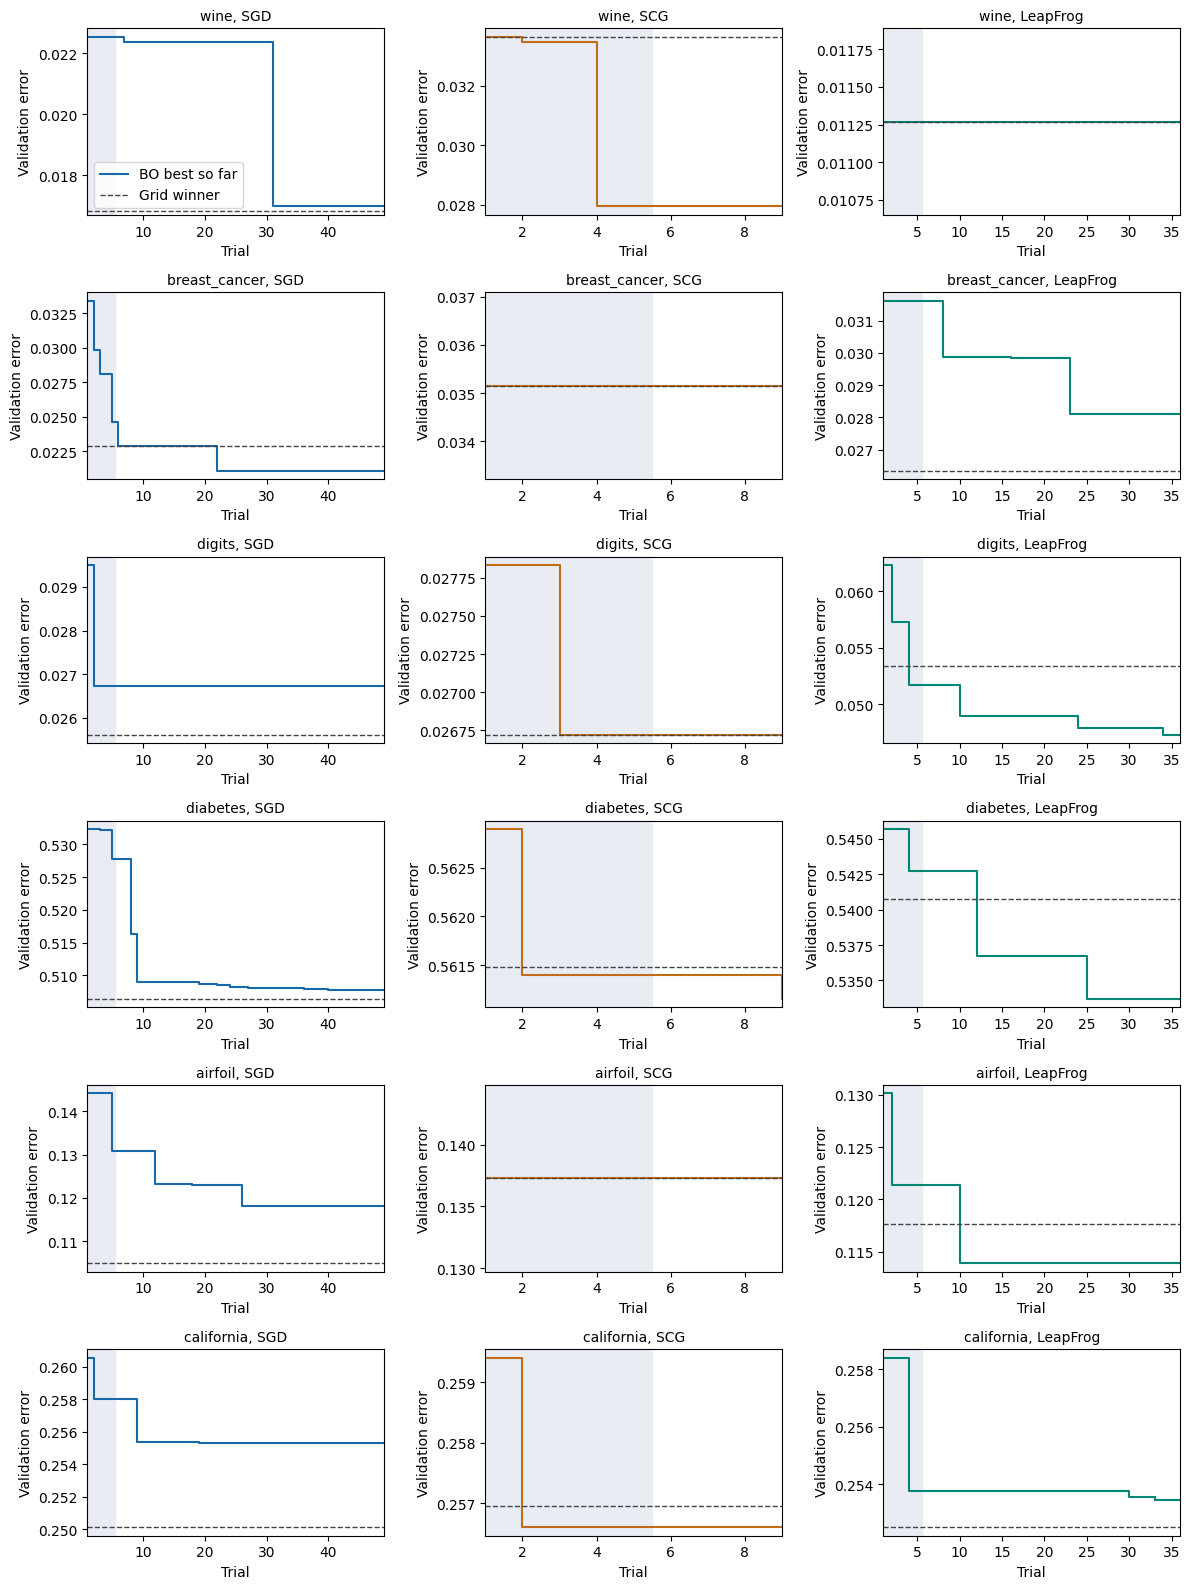

In [13]:
fig, axes = plt.subplots(6, 3, figsize=(12, 16))
for row, name in enumerate(PROBLEMS):
    for column, algorithm in enumerate(ALGORITHMS):
        ax = axes[row, column]
        part = trials[(trials["problem"] == name) & (trials["algorithm"] == algorithm)].sort_values("trial")
        errors = part["mean_val_error"].where(part["valid"], np.inf)
        best_so_far = np.minimum.accumulate(errors.values)
        grid_best = validation[(validation["problem"] == name) & (validation["algorithm"] == algorithm)]["grid_error"].iloc[0]
        ax.axvspan(0.5, 5.5, color="#e9edf3")
        ax.step(part["trial"], best_so_far, where="post", color=COLOURS[algorithm], label="BO best so far")
        ax.axhline(grid_best, linestyle="--", color="#444444", linewidth=1, label="Grid winner")
        ax.set_title(name + ", " + algorithm, fontsize=10)
        ax.set_xlim(1, part["trial"].max())
        ax.set_xlabel("Trial")
        ax.set_ylabel("Validation error")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "search_progress.png"), dpi=120)
plt.show()